# Task 3 — Advanced classifiers and feature selection

Random Forest, Gradient Boosting, soft voting and TabNet are studied separately.
Each feature selection method has its own GridSearch cell: **All features,
Filter, Redundancy, Logistic L1 and Logistic L2**.

The original classifier parameter grids are retained. Selection is now learned
**inside each CV training fold**, together with scaling and model fitting.
The test set is reserved before any training, using groups of identical bus states.

Run the preparation cells first, then the method sections in order.
Previous outputs and conclusions were cleared because the corrected splits change
the observations available for training and evaluation. No dataset values are edited.


## 1. Installation and imports

Run the installation cell only if the packages are missing. If Jupyter requests a
kernel restart, restart it before executing the remaining cells.


In [1]:
%pip install torch pytorch-tabnet


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import precision_score, recall_score, f1_score, make_scorer, confusion_matrix
from pytorch_tabnet.tab_model import TabNetClassifier


## 2. Data and group-aware splits — before any GridSearch

Keep your CSV filename below. All scenarios sharing the same bus-state values
receive the same group identifier. A group stays entirely in train, validation
or test. The approximate split is 64% / 16% / 20%; group sizes can change the row proportions.

`X` contains the explanatory variables; `y` is the binary `blackout` target.


In [3]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv("train.csv")  # Adapt the filename

X = df.drop(columns=["blackout"])
y = df["blackout"]

# Keep identical bus states together
bus_columns = [
    column for column in X.columns
    if column.startswith("bus_")
]

if not bus_columns:
    raise ValueError("No bus columns found.")

groups = pd.util.hash_pandas_object(
    X[bus_columns], index=False
).to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()
groups_train = groups[train_idx]

X_val = X.iloc[val_idx].copy()
y_val = y.iloc[val_idx].copy()
groups_val = groups[val_idx]

# Verify that neither rows nor bus states are shared
assert set(train_idx).isdisjoint(val_idx)
assert set(groups_train).isdisjoint(groups_val)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Shared rows: 0")
print("Shared bus states: 0")

Train: (12889, 224)
Validation: (3129, 224)
Shared rows: 0
Shared bus states: 0


## 3. Feature selection inside cross-validation

This small transformer contains the same selection steps used previously.
`fit()` learns the selected columns using only the current CV training fold;
`transform()` applies that list to other rows.

- **All features:** keep all explanatory variables.
- **Filter:** ANOVA, keep at most 50 nonconstant variables.
- **Redundancy:** keep variables with absolute correlation at most 0.95
  with the variables already retained, using the original column order.
- **Logistic L1:** standardize internally, fit L1 logistic regression, and keep
  coefficients with absolute value greater than `1e-6`.
- **Logistic L2:** standardize internally, fit L2 logistic regression, and keep
  coefficients whose absolute value is at least the mean absolute coefficient.

L2 usually shrinks coefficients without setting them to zero. The mean threshold
is therefore an explicit selection rule, not a claim that L2 automatically removes
variables. The L1 and L2 selectors use `C=0.1`, as in the previous L1 experiment.
These selector settings stay fixed; each model's hyperparameters are tuned jointly
with fitting its selector in every fold.


In [4]:
class FeatureSelector(TransformerMixin, BaseEstimator):

    def __init__(self, method="All features", k=50, correlation_threshold=0.95, C=0.1):
        self.method = method
        self.k = k
        self.correlation_threshold = correlation_threshold
        self.C = C

    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        variable_columns = X.columns[X.nunique() > 1].tolist()

        if self.method == "All features":
            self.selected_columns_ = X.columns.tolist()

        elif self.method == "Filter":
            selector = SelectKBest(f_classif, k=min(self.k, len(variable_columns)))
            selector.fit(X[variable_columns], y)
            self.selected_columns_ = np.array(variable_columns)[selector.get_support()].tolist()

        elif self.method == "Redundancy":
            correlations = X[variable_columns].corr().abs().fillna(0)
            self.selected_columns_ = []
            for column in variable_columns:
                if not self.selected_columns_ or (
                    correlations.loc[column, self.selected_columns_] <= self.correlation_threshold
                ).all():
                    self.selected_columns_.append(column)

        elif self.method in ["Logistic L1", "Logistic L2"]:
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X[variable_columns])
            penalty = "l1" if self.method == "Logistic L1" else "l2"
            selector = LogisticRegression(
                l1_ratio=1 if penalty == "l1" else 0, solver="liblinear", C=self.C,
                class_weight="balanced", max_iter=5000, random_state=42
            )
            selector.fit(X_scaled, y)
            importance = np.abs(selector.coef_[0])
            threshold = 1e-6 if penalty == "l1" else importance.mean()
            selected_mask = importance > 1e-6 if penalty == "l1" else importance >= threshold
            self.selected_columns_ = np.array(variable_columns)[selected_mask].tolist()

        else:
            raise ValueError(f"Unknown selection method: {self.method}")

        if not self.selected_columns_:
            raise ValueError(f"{self.method} selected no variables in this fold.")
        return self

    def transform(self, X):
        return X.loc[:, self.selected_columns_]

    def get_feature_names_out(self, input_features=None):
        return np.array(self.selected_columns_, dtype=object)


In [5]:
# The same three folds are used for all algorithms and selection methods
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
cv_folds = list(cv.split(X_train, y_train, groups=groups_train))

for train_indices, evaluation_indices in cv_folds:
    assert not (
        set(groups_train[train_indices]) & set(groups_train[evaluation_indices])
    )

scoring = {
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

methods = ["All features", "Filter", "Redundancy", "Logistic L1", "Logistic L2"]


## 4. Random Forest — one GridSearch for each method

The original Random Forest parameter values are retained, with a fixed random seed.
This is a large grid: 1,152 candidates per method, or 3,456 CV fits per method.
Run each method's cell separately if needed. Change the grid below only if you want
to reduce the computation budget.

Each search jointly fits its feature selection and tunes Random Forest inside CV.


In [6]:
param_grid = {
    "model__n_estimators": [2, 4, 6],
    "model__max_depth": [4, 8, 11, None],
    "model__min_samples_split": [2, 4, 6],
    "model__min_samples_leaf": [2, 3, 5, 7],
    "model__max_features": [200, 30, 100, 225],
    "model__class_weight": [None, "balanced"]
}

rf_searches = {}
print("RF candidates per method:", len(ParameterGrid(param_grid)))


RF candidates per method: 1152


### 4.1. Random Forest — All features


In [7]:
rf_all_pipeline = Pipeline([
    ("selection", FeatureSelector(method="All features")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_all_search = GridSearchCV(
    estimator=rf_all_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

rf_all_search.fit(X_train, y_train)
rf_searches["All features"] = rf_all_search

print("Best parameters:", rf_all_search.best_params_)
print("Best mean CV recall:", rf_all_search.best_score_)


Fitting 3 folds for each of 1152 candidates, totalling 3456 fits
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 11, 'model__max_features': 200, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 6}
Best mean CV recall: 0.9691200442479985


### 4.2. Random Forest — Filter


In [8]:
rf_filter_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Filter")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_filter_search = GridSearchCV(
    estimator=rf_filter_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

rf_filter_search.fit(X_train, y_train)
rf_searches["Filter"] = rf_filter_search

print("Best parameters:", rf_filter_search.best_params_)
print("Best mean CV recall:", rf_filter_search.best_score_)


Fitting 3 folds for each of 1152 candidates, totalling 3456 fits
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__max_features': 200, 'model__min_samples_leaf': 7, 'model__min_samples_split': 2, 'model__n_estimators': 4}
Best mean CV recall: 0.911053498941825


### 4.3. Random Forest — Redundancy


In [9]:
rf_redundancy_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Redundancy")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_redundancy_search = GridSearchCV(
    estimator=rf_redundancy_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

rf_redundancy_search.fit(X_train, y_train)
rf_searches["Redundancy"] = rf_redundancy_search

print("Best parameters:", rf_redundancy_search.best_params_)
print("Best mean CV recall:", rf_redundancy_search.best_score_)


Fitting 3 folds for each of 1152 candidates, totalling 3456 fits
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 11, 'model__max_features': 200, 'model__min_samples_leaf': 2, 'model__min_samples_split': 6, 'model__n_estimators': 6}
Best mean CV recall: 0.969870530698563


### 4.4. Random Forest — Logistic L1


In [11]:
rf_l1_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Logistic L1")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_l1_search = GridSearchCV(
    estimator=rf_l1_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

rf_l1_search.fit(X_train, y_train)
rf_searches["Logistic L1"] = rf_l1_search

print("Best parameters:", rf_l1_search.best_params_)
print("Best mean CV recall:", rf_l1_search.best_score_)


Fitting 3 folds for each of 1152 candidates, totalling 3456 fits
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 11, 'model__max_features': 200, 'model__min_samples_leaf': 2, 'model__min_samples_split': 6, 'model__n_estimators': 6}
Best mean CV recall: 0.9530169317347448


### 4.5. Random Forest — Logistic L2


In [12]:
rf_l2_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Logistic L2")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

rf_l2_search = GridSearchCV(
    estimator=rf_l2_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

rf_l2_search.fit(X_train, y_train)
rf_searches["Logistic L2"] = rf_l2_search

print("Best parameters:", rf_l2_search.best_params_)
print("Best mean CV recall:", rf_l2_search.best_score_)


Fitting 3 folds for each of 1152 candidates, totalling 3456 fits
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 11, 'model__max_features': 200, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 6}
Best mean CV recall: 0.9691147706282669


### 4.6. Random Forest — CV comparison

`CV` scores are averages over the held-out folds within `X_train`. They are not
test-set scores. Feature counts below come from the final refit on all training
rows; each fold may select a different number of variables.


In [17]:
rf_results = []
rf_trained_models = {}

for method, search in rf_searches.items():
    index = search.best_index_
    model = search.best_estimator_
    rf_trained_models[method] = model

    rf_results.append({
        "Algorithm": "Random Forest",
        "Method": method,
        "Features": len(model.named_steps["selection"].selected_columns_),
        "CV Precision": search.cv_results_["mean_test_precision"][index],
        "CV Recall": search.cv_results_["mean_test_recall"][index],
        "CV Recall std": search.cv_results_["std_test_recall"][index],
        "CV F1-score": search.cv_results_["mean_test_f1"][index],
        "Best parameters": search.best_params_
    })

rf_comparison = (
    pd.DataFrame(rf_results)
    .sort_values(["CV Recall", "CV Precision"], ascending=False)
    .reset_index(drop=True)
)

display(rf_comparison.round(4))


,Algorithm,Method,Features,CV Precision,CV Recall,CV Recall std,CV F1-score,Best parameters
0,Random Forest,Redundancy,123,0.7711,0.9699,0.0091,0.8590,"{'model__class_weight': 'balanced', 'model__ma..."
1,Random Forest,All features,224,0.7733,0.9691,0.0102,0.8601,"{'model__class_weight': 'balanced', 'model__ma..."
2,Random Forest,Logistic L2,80,0.7681,0.9691,0.0111,0.8568,"{'model__class_weight': 'balanced', 'model__ma..."
3,Random Forest,Logistic L1,97,0.8110,0.9530,0.0011,0.8763,"{'model__class_weight': 'balanced', 'model__ma..."
4,Random Forest,Filter,50,0.7336,0.9111,0.0185,0.8122,"{'model__class_weight': 'balanced', 'model__ma..."


In [18]:
# Familiar names retained for the following sections
trained_models = rf_trained_models
comparison = rf_comparison
grid_search = rf_searches[rf_comparison.iloc[0]["Method"]]
best_rf_method = rf_comparison.iloc[0]["Method"]
best_rf = grid_search.best_estimator_


## 5. Gradient Boosting — one GridSearch for each method

The original Gradient Boosting grid is retained: 8 candidates per method.


In [19]:
gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

gb_searches = {}


### 5.1. Gradient Boosting — All features


In [20]:
gb_all_pipeline = Pipeline([
    ("selection", FeatureSelector(method="All features")),
    ("model", GradientBoostingClassifier(min_samples_leaf=5, random_state=42))
])

gb_all_search = GridSearchCV(
    estimator=gb_all_pipeline,
    param_grid=gb_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

gb_all_search.fit(X_train, y_train)
gb_searches["All features"] = gb_all_search

print("Best parameters:", gb_all_search.best_params_)
print("Best mean CV recall:", gb_all_search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best mean CV recall: 0.9276527471693647


### 5.2. Gradient Boosting — Filter


In [21]:
gb_filter_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Filter")),
    ("model", GradientBoostingClassifier(min_samples_leaf=5, random_state=42))
])

gb_filter_search = GridSearchCV(
    estimator=gb_filter_pipeline,
    param_grid=gb_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

gb_filter_search.fit(X_train, y_train)
gb_searches["Filter"] = gb_filter_search

print("Best parameters:", gb_filter_search.best_params_)
print("Best mean CV recall:", gb_filter_search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best mean CV recall: 0.8068261349960264


### 5.3. Gradient Boosting — Redundancy


In [22]:
gb_redundancy_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Redundancy")),
    ("model", GradientBoostingClassifier(min_samples_leaf=5, random_state=42))
])

gb_redundancy_search = GridSearchCV(
    estimator=gb_redundancy_pipeline,
    param_grid=gb_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

gb_redundancy_search.fit(X_train, y_train)
gb_searches["Redundancy"] = gb_redundancy_search

print("Best parameters:", gb_redundancy_search.best_params_)
print("Best mean CV recall:", gb_redundancy_search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best mean CV recall: 0.9268872413892449


### 5.4. Gradient Boosting — Logistic L1


In [23]:
gb_l1_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Logistic L1")),
    ("model", GradientBoostingClassifier(min_samples_leaf=5, random_state=42))
])

gb_l1_search = GridSearchCV(
    estimator=gb_l1_pipeline,
    param_grid=gb_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

gb_l1_search.fit(X_train, y_train)
gb_searches["Logistic L1"] = gb_l1_search

print("Best parameters:", gb_l1_search.best_params_)
print("Best mean CV recall:", gb_l1_search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best mean CV recall: 0.9202867271901698


### 5.5. Gradient Boosting — Logistic L2


In [24]:
gb_l2_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Logistic L2")),
    ("model", GradientBoostingClassifier(min_samples_leaf=5, random_state=42))
])

gb_l2_search = GridSearchCV(
    estimator=gb_l2_pipeline,
    param_grid=gb_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

gb_l2_search.fit(X_train, y_train)
gb_searches["Logistic L2"] = gb_l2_search

print("Best parameters:", gb_l2_search.best_params_)
print("Best mean CV recall:", gb_l2_search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best mean CV recall: 0.9082135596461175


### 5.6. Gradient Boosting — CV comparison


In [25]:
gb_results = []
gb_trained_models = {}

for method, search in gb_searches.items():
    index = search.best_index_
    model = search.best_estimator_
    gb_trained_models[method] = model

    gb_results.append({
        "Algorithm": "Gradient Boosting",
        "Method": method,
        "Features": len(model.named_steps["selection"].selected_columns_),
        "CV Precision": search.cv_results_["mean_test_precision"][index],
        "CV Recall": search.cv_results_["mean_test_recall"][index],
        "CV Recall std": search.cv_results_["std_test_recall"][index],
        "CV F1-score": search.cv_results_["mean_test_f1"][index],
        "Best parameters": search.best_params_
    })

gb_comparison = (
    pd.DataFrame(gb_results)
    .sort_values(["CV Recall", "CV Precision"], ascending=False)
    .reset_index(drop=True)
)

display(gb_comparison.round(4))


,Algorithm,Method,Features,CV Precision,CV Recall,CV Recall std,CV F1-score,Best parameters
0,Gradient Boosting,All features,224,0.9835,0.9277,0.0095,0.9547,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,Gradient Boosting,Redundancy,123,0.9842,0.9269,0.0124,0.9546,"{'model__learning_rate': 0.1, 'model__max_dept..."
2,Gradient Boosting,Logistic L1,97,0.9890,0.9203,0.0096,0.9534,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,Gradient Boosting,Logistic L2,80,0.9758,0.9082,0.0086,0.9407,"{'model__learning_rate': 0.1, 'model__max_dept..."
4,Gradient Boosting,Filter,50,0.8803,0.8068,0.0120,0.8419,"{'model__learning_rate': 0.1, 'model__max_dept..."


In [26]:
best_gb_method = gb_comparison.iloc[0]["Method"]
gb_grid_search = gb_searches[best_gb_method]
best_gb = gb_grid_search.best_estimator_
gb_redundancy = gb_trained_models["Redundancy"]


## 6. Ensemble learning — RF + GB

For each method, combine its tuned RF and GB pipelines and search the three weights
`[1, 1]`, `[2, 1]`, `[1, 2]`. The same selection method is applied to both models;
there is no cross-product of different selection methods.

VotingClassifier retrains copies of the pipelines in each fold. Both selectors
are therefore fitted inside that fold. The classifier hyperparameters come from
the corresponding searches above; this stage tunes only the voting weights.


In [27]:
weight_grid = {"weights": [[1, 1], [2, 1], [1, 2]]}
voting_searches = {}


### 6.1. Soft voting — All features


In [28]:
voting_all_model = VotingClassifier(
    estimators=[
        ("rf", clone(rf_trained_models["All features"])),
        ("gb", clone(gb_trained_models["All features"]))
    ],
    voting="soft",
    n_jobs=1
)

voting_all_search = GridSearchCV(
    estimator=voting_all_model,
    param_grid=weight_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

voting_all_search.fit(X_train, y_train)
voting_searches["All features"] = voting_all_search

print("Best weights:", voting_all_search.best_params_)
print("Best mean CV recall:", voting_all_search.best_score_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best weights: {'weights': [2, 1]}
Best mean CV recall: 0.9640002100007655


### 6.2. Soft voting — Filter


In [29]:
voting_filter_model = VotingClassifier(
    estimators=[
        ("rf", clone(rf_trained_models["Filter"])),
        ("gb", clone(gb_trained_models["Filter"]))
    ],
    voting="soft",
    n_jobs=1
)

voting_filter_search = GridSearchCV(
    estimator=voting_filter_model,
    param_grid=weight_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

voting_filter_search.fit(X_train, y_train)
voting_searches["Filter"] = voting_filter_search

print("Best weights:", voting_filter_search.best_params_)
print("Best mean CV recall:", voting_filter_search.best_score_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best weights: {'weights': [2, 1]}
Best mean CV recall: 0.8699346762249967


### 6.3. Soft voting — Redundancy


In [30]:
voting_redundancy_model = VotingClassifier(
    estimators=[
        ("rf", clone(rf_trained_models["Redundancy"])),
        ("gb", clone(gb_trained_models["Redundancy"]))
    ],
    voting="soft",
    n_jobs=1
)

voting_redundancy_search = GridSearchCV(
    estimator=voting_redundancy_model,
    param_grid=weight_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

voting_redundancy_search.fit(X_train, y_train)
voting_searches["Redundancy"] = voting_redundancy_search

print("Best weights:", voting_redundancy_search.best_params_)
print("Best mean CV recall:", voting_redundancy_search.best_score_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best weights: {'weights': [2, 1]}
Best mean CV recall: 0.9658325704329699


### 6.4. Soft voting — Logistic L1


In [31]:
voting_l1_model = VotingClassifier(
    estimators=[
        ("rf", clone(rf_trained_models["Logistic L1"])),
        ("gb", clone(gb_trained_models["Logistic L1"]))
    ],
    voting="soft",
    n_jobs=1
)

voting_l1_search = GridSearchCV(
    estimator=voting_l1_model,
    param_grid=weight_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

voting_l1_search.fit(X_train, y_train)
voting_searches["Logistic L1"] = voting_l1_search

print("Best weights:", voting_l1_search.best_params_)
print("Best mean CV recall:", voting_l1_search.best_score_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best weights: {'weights': [2, 1]}
Best mean CV recall: 0.9497149030320574


### 6.5. Soft voting — Logistic L2


In [32]:
voting_l2_model = VotingClassifier(
    estimators=[
        ("rf", clone(rf_trained_models["Logistic L2"])),
        ("gb", clone(gb_trained_models["Logistic L2"]))
    ],
    voting="soft",
    n_jobs=1
)

voting_l2_search = GridSearchCV(
    estimator=voting_l2_model,
    param_grid=weight_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

voting_l2_search.fit(X_train, y_train)
voting_searches["Logistic L2"] = voting_l2_search

print("Best weights:", voting_l2_search.best_params_)
print("Best mean CV recall:", voting_l2_search.best_score_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best weights: {'weights': [2, 1]}
Best mean CV recall: 0.9632594692600248


### 6.6. Soft voting — CV comparison


In [33]:
voting_results = []
voting_trained_models = {}

for method, search in voting_searches.items():
    index = search.best_index_
    model = search.best_estimator_
    voting_trained_models[method] = model

    voting_results.append({
        "Algorithm": "Soft Voting RF + GB",
        "Method": method,
        "RF features": len(model.named_estimators_["rf"].named_steps["selection"].selected_columns_),
        "GB features": len(model.named_estimators_["gb"].named_steps["selection"].selected_columns_),
        "Weights": search.best_params_["weights"],
        "CV Precision": search.cv_results_["mean_test_precision"][index],
        "CV Recall": search.cv_results_["mean_test_recall"][index],
        "CV Recall std": search.cv_results_["std_test_recall"][index],
        "CV F1-score": search.cv_results_["mean_test_f1"][index]
    })

voting_comparison = (
    pd.DataFrame(voting_results)
    .sort_values(["CV Recall", "CV Precision"], ascending=False)
    .reset_index(drop=True)
)

display(voting_comparison.round(4))

best_voting_method = voting_comparison.iloc[0]["Method"]
best_voting = voting_trained_models[best_voting_method]


,Algorithm,Method,RF features,GB features,Weights,CV Precision,CV Recall,CV Recall std,CV F1-score
0,Soft Voting RF + GB,Redundancy,123,123,"[2, 1]",0.8389,0.9658,0.0071,0.8976
1,Soft Voting RF + GB,All features,224,224,"[2, 1]",0.8337,0.9640,0.0069,0.8940
2,Soft Voting RF + GB,Logistic L2,80,80,"[2, 1]",0.8319,0.9633,0.0074,0.8927
3,Soft Voting RF + GB,Logistic L1,97,97,"[2, 1]",0.8460,0.9497,0.0033,0.8948
4,Soft Voting RF + GB,Filter,50,50,"[2, 1]",0.8140,0.8699,0.0204,0.8405


## 7. TabNet — one GridSearch for each method

TabNet is the additional deep learning algorithm for tabular data.

Reference: Arik, S. O. and Pfister, T. (2021),
[TabNet: Attentive Interpretable Tabular Learning](https://arxiv.org/abs/1908.07442), AAAI.
The library implementation may differ from the original research implementation.

The original grid is retained: four architecture configurations per method.
Each configuration uses 40 epochs, automatic class-balanced sampling and no early
stopping during CV. No external validation observations are passed to CV training.
`drop_last=True` avoids a final training batch containing just one observation.


In [34]:
# Ensure classifier compatibility with recent scikit-learn versions
class TabNetForGrid(ClassifierMixin, TabNetClassifier):
    pass


tabnet_param_grid = [
    {
        "model__n_d": [width],
        "model__n_a": [width],
        "model__n_steps": [3, 5]
    }
    for width in [8, 16]
]

tabnet_fit_parameters = {
    "model__weights": 1,
    "model__max_epochs": 40,
    "model__patience": 0,
    "model__batch_size": 256,
    "model__virtual_batch_size": 64,
    "model__num_workers": 0,
    "model__drop_last": True,
    "model__compute_importance": False
}

tabnet_searches = {}


### 7.1. TabNet — All features


In [35]:
tabnet_all_pipeline = Pipeline([
    ("selection", FeatureSelector(method="All features")),
    ("scaler", StandardScaler()),
    ("float32", FunctionTransformer(np.asarray, kw_args={"dtype": np.float32})),
    ("model", TabNetForGrid(
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": 0.02},
        lambda_sparse=1e-3,
        seed=42,
        verbose=0,
        device_name="auto"
    ))
])

tabnet_all_search = GridSearchCV(
    estimator=tabnet_all_pipeline,
    param_grid=tabnet_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

tabnet_all_search.fit(X_train, y_train.to_numpy(), **tabnet_fit_parameters)
tabnet_searches["All features"] = tabnet_all_search

print("Best parameters:", tabnet_all_search.best_params_)
print("Best mean CV recall:", tabnet_all_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 2.1min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 2.1min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


... (17 outputs left out)

C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .....model__n_a=16, model__n_d=16, model__n_steps=5; total time= 3.2min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


Best parameters: {'model__n_a': 16, 'model__n_d': 16, 'model__n_steps': 5}
Best mean CV recall: 0.9871579932031177


### 7.2. TabNet — Filter


In [36]:
tabnet_filter_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Filter")),
    ("scaler", StandardScaler()),
    ("float32", FunctionTransformer(np.asarray, kw_args={"dtype": np.float32})),
    ("model", TabNetForGrid(
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": 0.02},
        lambda_sparse=1e-3,
        seed=42,
        verbose=0,
        device_name="auto"
    ))
])

tabnet_filter_search = GridSearchCV(
    estimator=tabnet_filter_pipeline,
    param_grid=tabnet_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

tabnet_filter_search.fit(X_train, y_train.to_numpy(), **tabnet_fit_parameters)
tabnet_searches["Filter"] = tabnet_filter_search

print("Best parameters:", tabnet_filter_search.best_params_)
print("Best mean CV recall:", tabnet_filter_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.5min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.6min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


... (17 outputs left out)

C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .....model__n_a=16, model__n_d=16, model__n_steps=5; total time= 2.5min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


Best parameters: {'model__n_a': 8, 'model__n_d': 8, 'model__n_steps': 5}
Best mean CV recall: 0.8935021946994756


### 7.3. TabNet — Redundancy


In [37]:
tabnet_redundancy_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Redundancy")),
    ("scaler", StandardScaler()),
    ("float32", FunctionTransformer(np.asarray, kw_args={"dtype": np.float32})),
    ("model", TabNetForGrid(
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": 0.02},
        lambda_sparse=1e-3,
        seed=42,
        verbose=0,
        device_name="auto"
    ))
])

tabnet_redundancy_search = GridSearchCV(
    estimator=tabnet_redundancy_pipeline,
    param_grid=tabnet_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

tabnet_redundancy_search.fit(X_train, y_train.to_numpy(), **tabnet_fit_parameters)
tabnet_searches["Redundancy"] = tabnet_redundancy_search

print("Best parameters:", tabnet_redundancy_search.best_params_)
print("Best mean CV recall:", tabnet_redundancy_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.7min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.7min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


... (17 outputs left out)

C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .....model__n_a=16, model__n_d=16, model__n_steps=5; total time= 2.7min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


Best parameters: {'model__n_a': 8, 'model__n_d': 8, 'model__n_steps': 3}
Best mean CV recall: 0.9798103260261883


### 7.4. TabNet — Logistic L1


In [38]:
tabnet_l1_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Logistic L1")),
    ("scaler", StandardScaler()),
    ("float32", FunctionTransformer(np.asarray, kw_args={"dtype": np.float32})),
    ("model", TabNetForGrid(
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": 0.02},
        lambda_sparse=1e-3,
        seed=42,
        verbose=0,
        device_name="auto"
    ))
])

tabnet_l1_search = GridSearchCV(
    estimator=tabnet_l1_pipeline,
    param_grid=tabnet_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

tabnet_l1_search.fit(X_train, y_train.to_numpy(), **tabnet_fit_parameters)
tabnet_searches["Logistic L1"] = tabnet_l1_search

print("Best parameters:", tabnet_l1_search.best_params_)
print("Best mean CV recall:", tabnet_l1_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.7min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.7min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


... (17 outputs left out)

C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .....model__n_a=16, model__n_d=16, model__n_steps=5; total time= 2.6min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


Best parameters: {'model__n_a': 8, 'model__n_d': 8, 'model__n_steps': 3}
Best mean CV recall: 0.9889623824773864


### 7.5. TabNet — Logistic L2


In [39]:
tabnet_l2_pipeline = Pipeline([
    ("selection", FeatureSelector(method="Logistic L2")),
    ("scaler", StandardScaler()),
    ("float32", FunctionTransformer(np.asarray, kw_args={"dtype": np.float32})),
    ("model", TabNetForGrid(
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": 0.02},
        lambda_sparse=1e-3,
        seed=42,
        verbose=0,
        device_name="auto"
    ))
])

tabnet_l2_search = GridSearchCV(
    estimator=tabnet_l2_pipeline,
    param_grid=tabnet_param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_folds,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

tabnet_l2_search.fit(X_train, y_train.to_numpy(), **tabnet_fit_parameters)
tabnet_searches["Logistic L2"] = tabnet_l2_search

print("Best parameters:", tabnet_l2_search.best_params_)
print("Best mean CV recall:", tabnet_l2_search.best_score_)


Fitting 3 folds for each of 4 candidates, totalling 12 fits


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.6min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .......model__n_a=8, model__n_d=8, model__n_steps=3; total time= 1.6min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


... (17 outputs left out)

C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


[CV] END .....model__n_a=16, model__n_d=16, model__n_steps=5; total time= 2.5min


C:\Users\anais\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:687: UserWarning: No early stopping will be performed, last training weights will be used.
  warnings.warn(wrn_msg)


Best parameters: {'model__n_a': 16, 'model__n_d': 16, 'model__n_steps': 3}
Best mean CV recall: 0.9889457600885528


### 7.6. TabNet — CV comparison


In [40]:
tabnet_results = []
tabnet_trained_models = {}

for method, search in tabnet_searches.items():
    index = search.best_index_
    model = search.best_estimator_
    tabnet_trained_models[method] = model

    tabnet_results.append({
        "Algorithm": "TabNet",
        "Method": method,
        "Features": len(model.named_steps["selection"].selected_columns_),
        "CV Precision": search.cv_results_["mean_test_precision"][index],
        "CV Recall": search.cv_results_["mean_test_recall"][index],
        "CV Recall std": search.cv_results_["std_test_recall"][index],
        "CV F1-score": search.cv_results_["mean_test_f1"][index],
        "Best parameters": search.best_params_
    })

tabnet_comparison = (
    pd.DataFrame(tabnet_results)
    .sort_values(["CV Recall", "CV Precision"], ascending=False)
    .reset_index(drop=True)
)

display(tabnet_comparison.round(4))


,Algorithm,Method,Features,CV Precision,CV Recall,CV Recall std,CV F1-score,Best parameters
0,TabNet,Logistic L1,97,0.9123,0.9890,0.0040,0.9489,"{'model__n_a': 8, 'model__n_d': 8, 'model__n_s..."
1,TabNet,Logistic L2,80,0.8916,0.9889,0.0066,0.9376,"{'model__n_a': 16, 'model__n_d': 16, 'model__n..."
2,TabNet,All features,224,0.9054,0.9872,0.0045,0.9443,"{'model__n_a': 16, 'model__n_d': 16, 'model__n..."
3,TabNet,Redundancy,123,0.9438,0.9798,0.0004,0.9614,"{'model__n_a': 8, 'model__n_d': 8, 'model__n_s..."
4,TabNet,Filter,50,0.6721,0.8935,0.0346,0.7664,"{'model__n_a': 8, 'model__n_d': 8, 'model__n_s..."


In [41]:
best_tabnet_method = tabnet_comparison.iloc[0]["Method"]
tabnet_grid = tabnet_searches[best_tabnet_method]
best_tabnet_pipeline = tabnet_grid.best_estimator_
tabnet_selected_models = tabnet_trained_models


## 8. Compare the selected candidates on validation

First select one feature method per algorithm using its mean CV recall, then
precision to break ties between methods. Only now evaluate the four selected
candidates on `X_val`. These are validation scores, not final test scores.

The CV scores were used for tuning and method selection. They are not an
independent estimate of the entire tuning procedure; use the reserved test for
the final evaluation, or nested CV if an independent CV estimate is required.
All predictions below use the explicit decision rule `probability >= 0.50`.


In [42]:
cv_comparison = pd.concat([
    rf_comparison, gb_comparison, voting_comparison, tabnet_comparison
], ignore_index=True)

display(cv_comparison.sort_values(
    ["CV Recall", "CV Precision"], ascending=False
).reset_index(drop=True).round(4))

candidate_models = {
    "Random Forest": best_rf,
    "Gradient Boosting": best_gb,
    "Soft Voting RF + GB": best_voting,
    "TabNet": best_tabnet_pipeline
}

candidate_methods = {
    "Random Forest": best_rf_method,
    "Gradient Boosting": best_gb_method,
    "Soft Voting RF + GB": best_voting_method,
    "TabNet": best_tabnet_method
}

validation_results = []
validation_probabilities = {}

for algorithm, model in candidate_models.items():
    positive_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_val)[:, positive_index]
    validation_probabilities[algorithm] = probabilities
    predictions = (probabilities >= 0.50).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    validation_results.append({
        "Algorithm": algorithm,
        "Method": candidate_methods[algorithm],
        "Threshold": 0.50,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "False positives": fp,
        "False negatives": fn
    })

validation_comparison = (
    pd.DataFrame(validation_results)
    .sort_values(["Recall", "Precision"], ascending=False)
    .reset_index(drop=True)
)

display(validation_comparison.round(4))


,Algorithm,Method,Features,CV Precision,CV Recall,CV Recall std,CV F1-score,Best parameters,RF features,GB features,Weights
0,TabNet,Logistic L1,97.0,0.9123,0.9890,0.0040,0.9489,"{'model__n_a': 8, 'model__n_d': 8, 'model__n_s...",NaN,NaN,NaN
1,TabNet,Logistic L2,80.0,0.8916,0.9889,0.0066,0.9376,"{'model__n_a': 16, 'model__n_d': 16, 'model__n...",NaN,NaN,NaN
2,TabNet,All features,224.0,0.9054,0.9872,0.0045,0.9443,"{'model__n_a': 16, 'model__n_d': 16, 'model__n...",NaN,NaN,NaN
3,TabNet,Redundancy,123.0,0.9438,0.9798,0.0004,0.9614,"{'model__n_a': 8, 'model__n_d': 8, 'model__n_s...",NaN,NaN,NaN
4,Random Forest,Redundancy,123.0,0.7711,0.9699,0.0091,0.8590,"{'model__class_weight': 'balanced', 'model__ma...",NaN,NaN,NaN
5,Random Forest,All features,224.0,0.7733,0.9691,0.0102,0.8601,"{'model__class_weight': 'balanced', 'model__ma...",NaN,NaN,NaN
6,Random Forest,Logistic L2,80.0,0.7681,0.9691,0.0111,0.8568,"{'model__class_weight': 'balanced', 'model__ma...",NaN,NaN,NaN
7,Soft Voting RF + GB,Redundancy,NaN,0.8389,0.9658,0.0071,0.8976,NaN,123.0,123.0,"[2, 1]"
8,Soft Voting RF + GB,All features,NaN,0.8337,0.9640,0.0069,0.8940,NaN,224.0,224.0,"[2, 1]"
9,Soft Voting RF + GB,Logistic L2,NaN,0.8319,0.9633,0.0074,0.8927,NaN,80.0,80.0,"[2, 1]"


,Algorithm,Method,Threshold,Precision,Recall,F1-score,False positives,False negatives
0,TabNet,Logistic L1,0.5,0.8567,0.9961,0.9211,86,2
1,Soft Voting RF + GB,Redundancy,0.5,0.8364,0.9806,0.9028,99,10
2,Random Forest,Redundancy,0.5,0.7909,0.9748,0.8733,133,13
3,Gradient Boosting,All features,0.5,0.9857,0.9380,0.9613,7,32


## 9. Decision thresholds on validation

The threshold analysis from the original notebook is retained for the four
selected candidates. Use these results to discuss the cost of missed positive
cases and false alarms. Do not choose a threshold using test results.


In [43]:
threshold_results = []

for algorithm, probabilities in validation_probabilities.items():
    for threshold in np.round(np.arange(0.05, 0.55, 0.05), 2):
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

        threshold_results.append({
            "Algorithm": algorithm,
            "Method": candidate_methods[algorithm],
            "Threshold": threshold,
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1-score": f1_score(y_val, predictions, zero_division=0),
            "False positives": fp,
            "False negatives": fn
        })

threshold_comparison = pd.DataFrame(threshold_results)

for algorithm in candidate_models:
    print(algorithm)
    display(threshold_comparison[
        threshold_comparison["Algorithm"] == algorithm
    ].round(4))


Random Forest


,Algorithm,Method,Threshold,Precision,Recall,F1-score,False positives,False negatives
0,Random Forest,Redundancy,0.05,0.5777,0.9942,0.7308,375,3
1,Random Forest,Redundancy,0.10,0.5953,0.9922,0.7442,348,4
2,Random Forest,Redundancy,0.15,0.6214,0.9922,0.7642,312,4
3,Random Forest,Redundancy,0.20,0.6384,0.9922,0.7769,290,4
4,Random Forest,Redundancy,0.25,0.6531,0.9922,0.7877,272,4
5,Random Forest,Redundancy,0.30,0.6934,0.9903,0.8156,226,5
6,Random Forest,Redundancy,0.35,0.7286,0.9884,0.8388,190,6
7,Random Forest,Redundancy,0.40,0.7601,0.9884,0.8593,161,6
8,Random Forest,Redundancy,0.45,0.7623,0.9884,0.8608,159,6
9,Random Forest,Redundancy,0.50,0.7909,0.9748,0.8733,133,13


Gradient Boosting


,Algorithm,Method,Threshold,Precision,Recall,F1-score,False positives,False negatives
10,Gradient Boosting,All features,0.05,0.5519,1.0000,0.7112,419,0
11,Gradient Boosting,All features,0.10,0.6952,0.9903,0.8169,224,5
12,Gradient Boosting,All features,0.15,0.7904,0.9864,0.8776,135,7
13,Gradient Boosting,All features,0.20,0.8473,0.9787,0.9083,91,11
14,Gradient Boosting,All features,0.25,0.8922,0.9787,0.9335,61,11
15,Gradient Boosting,All features,0.30,0.9367,0.9748,0.9554,34,13
16,Gradient Boosting,All features,0.35,0.9598,0.9709,0.9653,21,15
17,Gradient Boosting,All features,0.40,0.9785,0.9690,0.9737,11,16
18,Gradient Boosting,All features,0.45,0.9839,0.9477,0.9654,8,27
19,Gradient Boosting,All features,0.50,0.9857,0.9380,0.9613,7,32


Soft Voting RF + GB


,Algorithm,Method,Threshold,Precision,Recall,F1-score,False positives,False negatives
20,Soft Voting RF + GB,Redundancy,0.05,0.5677,1.0000,0.7242,393,0
21,Soft Voting RF + GB,Redundancy,0.10,0.6076,0.9961,0.7548,332,2
22,Soft Voting RF + GB,Redundancy,0.15,0.6369,0.9961,0.7770,293,2
23,Soft Voting RF + GB,Redundancy,0.20,0.6675,0.9922,0.7981,255,4
24,Soft Voting RF + GB,Redundancy,0.25,0.7052,0.9922,0.8245,214,4
25,Soft Voting RF + GB,Redundancy,0.30,0.7474,0.9922,0.8526,173,4
26,Soft Voting RF + GB,Redundancy,0.35,0.7734,0.9922,0.8693,150,4
27,Soft Voting RF + GB,Redundancy,0.40,0.8250,0.9864,0.8985,108,7
28,Soft Voting RF + GB,Redundancy,0.45,0.8260,0.9845,0.8983,107,8
29,Soft Voting RF + GB,Redundancy,0.50,0.8364,0.9806,0.9028,99,10


TabNet


,Algorithm,Method,Threshold,Precision,Recall,F1-score,False positives,False negatives
30,TabNet,Logistic L1,0.05,0.7823,0.9961,0.8764,143,2
31,TabNet,Logistic L1,0.10,0.8019,0.9961,0.8885,127,2
32,TabNet,Logistic L1,0.15,0.8082,0.9961,0.8924,122,2
33,TabNet,Logistic L1,0.20,0.8185,0.9961,0.8986,114,2
34,TabNet,Logistic L1,0.25,0.8317,0.9961,0.9065,104,2
35,TabNet,Logistic L1,0.30,0.8358,0.9961,0.9089,101,2
36,TabNet,Logistic L1,0.35,0.8468,0.9961,0.9154,93,2
37,TabNet,Logistic L1,0.40,0.8468,0.9961,0.9154,93,2
38,TabNet,Logistic L1,0.45,0.8496,0.9961,0.9170,91,2
39,TabNet,Logistic L1,0.50,0.8567,0.9961,0.9211,86,2


## 10. Gradient Boosting feature importance

Keep the original importance analysis, now using the selected GB pipeline.
These importances describe the trained model; they do not establish causation.


,Importance
line_5_reactive_power_flow,0.268238
line_10_reactive_power_flow,0.085799
line_9_reactive_power_flow,0.031366
line_10_reactance,0.025290
line_10_rating,0.023653
line_11_reactance,0.023140
line_2_reactive_power_flow,0.021618
line_19_active_power_flow,0.020519
line_22_active_power_flow,0.017867
line_8_reactive_power_flow,0.017450


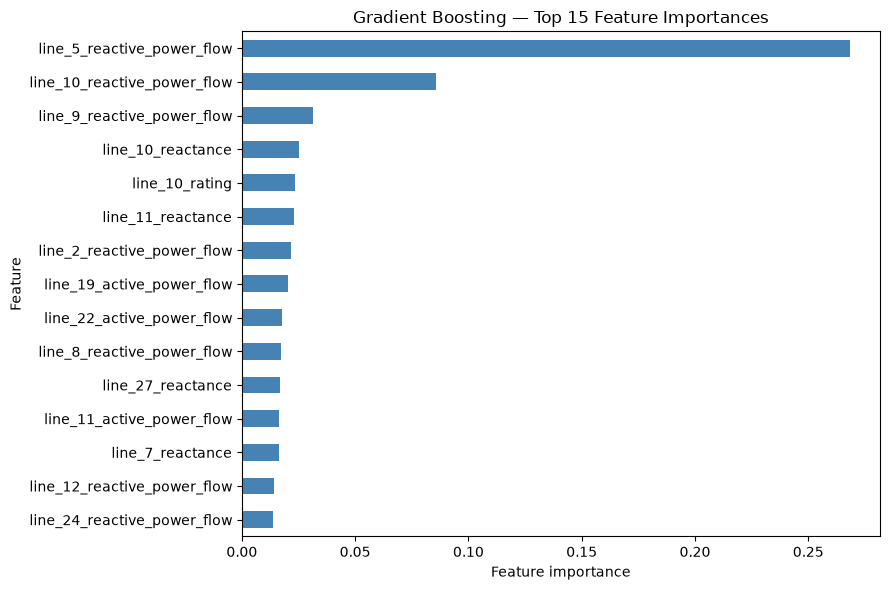

In [44]:
gb_columns = best_gb.named_steps["selection"].selected_columns_

gb_importances = pd.Series(
    best_gb.named_steps["model"].feature_importances_,
    index=gb_columns,
    name="Importance"
).sort_values(ascending=False)

display(gb_importances.head(15).to_frame())

gb_importances.head(15).sort_values().plot.barh(figsize=(9, 6), color="steelblue")
plt.title("Gradient Boosting — Top 15 Feature Importances")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 11. Next step: freeze the choice before the final test

Write the conclusion only after running the corrected notebook. State the chosen
algorithm, selection method, threshold, validation recall, precision, false
positives and false negatives. Explain the trade-off rather than selecting a model
only because its recall is highest.

The old conclusion and old scores do not apply automatically to these corrected
splits. The notebook reserves `X_test` and `y_test` but does not use them to make
selection or tuning decisions. The final evaluation belongs to the next project
step, after the complete configuration has been fixed.

Keep the baseline on the same corrected splits for the final project comparison.
